In [7]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMSkillsNetwork-AI0272EN-SkillsNetwork/labs/dataset/2016.csv"

In [11]:
import pandas as pd

# Load your data (change 'your_file.csv' to your actual filename)
df = pd.read_csv('2016.csv')

# Look at the first 5 rows to make sure it loaded correctly
df.head()

,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.590,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463
2,Iceland,Western Europe,3,7.501,7.333,7.669,1.42666,1.18326,0.86733,0.56624,0.14975,0.47678,2.83137
3,Norway,Western Europe,4,7.498,7.421,7.575,1.57744,1.12690,0.79579,0.59609,0.35776,0.37895,2.66465
4,Finland,Western Europe,5,7.413,7.351,7.475,1.40598,1.13464,0.81091,0.57104,0.41004,0.25492,2.82596


In [15]:
import pandas as pd

# 1. LOAD DATA
# Replace 'your_data.csv' with your actual filename (e.g., 'sales_data.csv')
df = pd.read_csv('2016.csv')

# 2. CHECK DATA TYPES
print("--- COLUMN DATA TYPES ---")
print(df.dtypes)
print("\n")

# 3. DETAILED INSPECTION
# This shows non-null counts and memory usage as well
print("--- DATASET SUMMARY ---")
df.info()

--- COLUMN DATA TYPES ---
Country                           object
Region                            object
Happiness Rank                     int64
Happiness Score                  float64
Lower Confidence Interval        float64
Upper Confidence Interval        float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float64
Generosity                       float64
Dystopia Residual                float64
dtype: object


--- DATASET SUMMARY ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        157 non-null    object 
 1   Region                         157 non-null    object 
 2   Happiness Rank                 157 non-null    int6

In [19]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('2016.csv')

# 1. Remove leading and trailing whitespaces from values in object columns
# This selects all text-based columns and strips extra spaces
object_cols = df.select_dtypes(include=['object']).columns
for col in object_cols:
    df[col] = df[col].str.strip()

# 2. Replace empty strings with NaN values
# Using regex to catch strings that are empty ("") or just whitespace ("  ")
df = df.replace(r'^\s*$', np.nan, regex=True)

# 3. Change data types to appropriate types as per latest pandas
# convert_dtypes() will use the new 'string' type and 'Int64'/'Float64' nullable types
df_cleaned = df.convert_dtypes()

# Display the new data types to verify
print("--- Updated Data Types ---")
print(df_cleaned.dtypes)

# Save the cleaned file
df_cleaned.to_csv('cleaned_2016.csv', index=False)

--- Updated Data Types ---
Country                          string[python]
Region                           string[python]
Happiness Rank                            Int64
Happiness Score                         Float64
Lower Confidence Interval               Float64
Upper Confidence Interval               Float64
Economy (GDP per Capita)                Float64
Family                                  Float64
Health (Life Expectancy)                Float64
Freedom                                 Float64
Trust (Government Corruption)           Float64
Generosity                              Float64
Dystopia Residual                       Float64
dtype: object


In [21]:
import pandas as pd
import numpy as np

# Load your previously cleaned data
df = pd.read_csv('cleaned_2016.csv')

# 1. Identify columns with missing values
missing_counts = df.isnull().sum()
cols_with_missing = missing_counts[missing_counts > 0].index.tolist()

print(f"Columns containing missing values: {cols_with_missing}")

# 2. Replace missing values with the mean (latest pandas approach)
# We select only numeric columns to calculate means safely
numeric_df = df.select_dtypes(include=[np.number])
df[numeric_df.columns] = df[numeric_df.columns].fillna(numeric_df.mean())

# Verify there are no more missing values in numeric columns
print("\nCheck for missing values after imputation:")
print(df.isnull().sum())

# Save the final version
df.to_csv('final_2016_imputed.csv', index=False)

Columns containing missing values: []

Check for missing values after imputation:
Country                          0
Region                           0
Happiness Rank                   0
Happiness Score                  0
Lower Confidence Interval        0
Upper Confidence Interval        0
Economy (GDP per Capita)         0
Family                           0
Health (Life Expectancy)         0
Freedom                          0
Trust (Government Corruption)    0
Generosity                       0
Dystopia Residual                0
dtype: int64


In [25]:
!pip install plotly

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.9 MB 699.0 kB/s eta 0:00:14
   --- ------------------------------------ 0.8/9.9 MB 798.0 kB/s eta 0:00:12
   --- ------------------------------------ 0.8/9.9 MB 798.0 kB/s eta 0:00:12
   ---- ----------------------------------- 1.0/9.9 MB 867.1 kB/s eta 0:00:11
   ----- ---------------------------------- 1.3/9.9 MB 944.7 kB/s eta 0:00:10
   ------- -------------------------------- 1.8/9.9 MB 1.0 MB/s eta 0:00:08
   -------- ------------------------------- 2.1/9.9 MB 1.1 MB/s eta 0:00:08
   --------- ------------------------------ 2.4/9.9 MB 1.1 MB/s eta 0:00:07
   ----------- ---------------------------- 2.9/9.9 MB 1.2 MB/s eta 0:00:06
   ------------ --------------

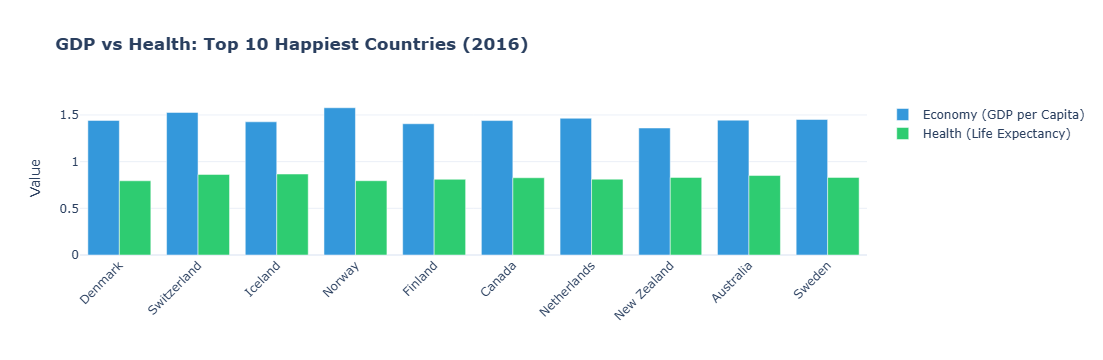

In [31]:
import pandas as pd
import plotly.express as px

# 1. Load the cleaned and imputed data
df = pd.read_csv('final_2016_imputed.csv')

# 2. Identify the top 10 countries by Happiness Rank
top_10 = df.nsmallest(10, 'Happiness Rank')

# 3. Prepare data for a grouped bar chart (melting)
top_10_melted = top_10.melt(
    id_vars='Country', 
    value_vars=['Economy (GDP per Capita)', 'Health (Life Expectancy)'],
    var_name='Metric', 
    value_name='Score'
)

# 4. Create the professional bar chart
fig1 = px.bar(
    top_10_melted, 
    x='Country', 
    y='Score', 
    color='Metric', 
    barmode='group',
    title='<b>GDP vs Health: Top 10 Happiest Countries (2016)</b>',
    labels={'Score': 'Value', 'Country': ''},
    color_discrete_map={
        'Economy (GDP per Capita)': '#3498db', # Professional Blue
        'Health (Life Expectancy)': '#2ecc71'  # Professional Green
    },
    template='plotly_white'
)

# 5. Polish the layout
fig1.update_layout(
    legend_title_text='',
    xaxis_tickangle=-45,
    font=dict(size=12),
    hovermode="x unified"
)

# Show the interactive chart
fig1.show()

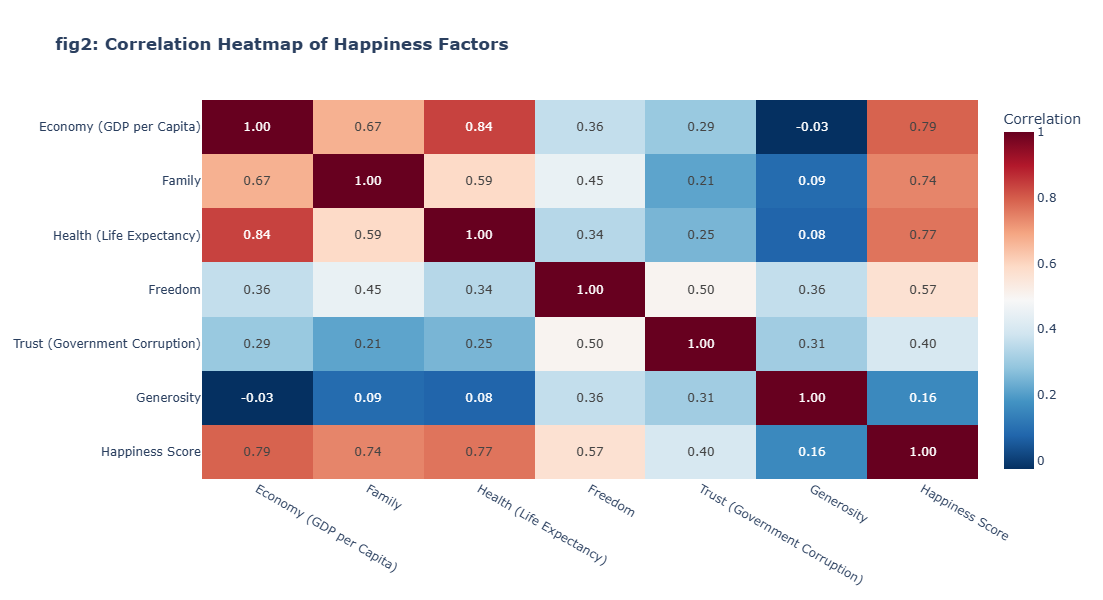

In [35]:
import pandas as pd
import plotly.express as px

# 1. Load the data
df = pd.read_csv('final_2016_imputed.csv')

# 2. Create the sub-dataset with specific attributes
sub_cols = [
    'Economy (GDP per Capita)', 
    'Family', 
    'Health (Life Expectancy)', 
    'Freedom', 
    'Trust (Government Corruption)', 
    'Generosity', 
    'Happiness Score'
]
sub_df = df[sub_cols]

# 3. Calculate the correlation matrix
corr_matrix = sub_df.corr()

# 4. Create the Heatmap (fig2)
fig2 = px.imshow(
    corr_matrix,
    text_auto='.2f', # Shows the correlation numbers on the heatmap
    aspect="auto",
    color_continuous_scale='RdBu_r', # Red for negative, Blue for positive
    labels=dict(color="Correlation"),
    title="<b>fig2: Correlation Heatmap of Happiness Factors</b>",
    width=800,
    height=600
)

# Show the interactive chart
fig2.show()

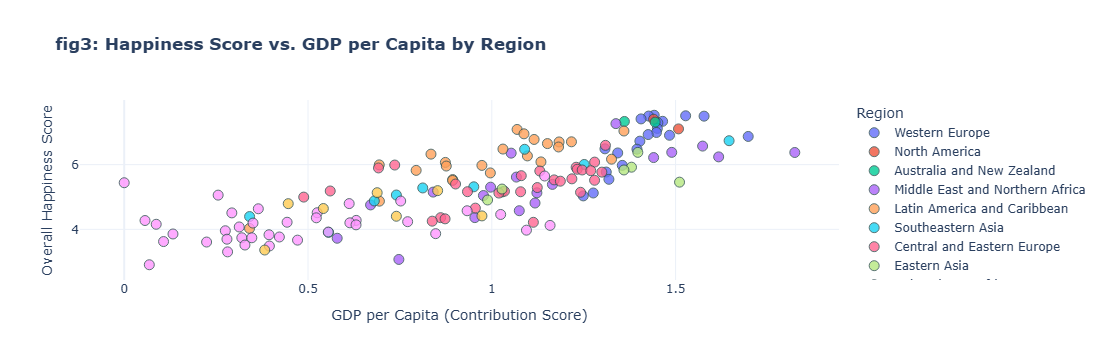

In [37]:
import pandas as pd
import plotly.express as px

# 1. Load the data
df = pd.read_csv('final_2016_imputed.csv')

# 2. Create the interactive scatter plot
fig3 = px.scatter(
    df, 
    x="Economy (GDP per Capita)", 
    y="Happiness Score", 
    color="Region",
    hover_name="Country", # Shows the country name when you hover
    title="<b>fig3: Happiness Score vs. GDP per Capita by Region</b>",
    labels={
        "Economy (GDP per Capita)": "GDP per Capita (Contribution Score)",
        "Happiness Score": "Overall Happiness Score"
    },
    template="plotly_white"
)

# 3. Update marker size and layout for a professional look
fig3.update_traces(marker=dict(size=10, opacity=0.8, line=dict(width=1, color='DarkSlateGrey')))

# 4. Show the chart
fig3.show()

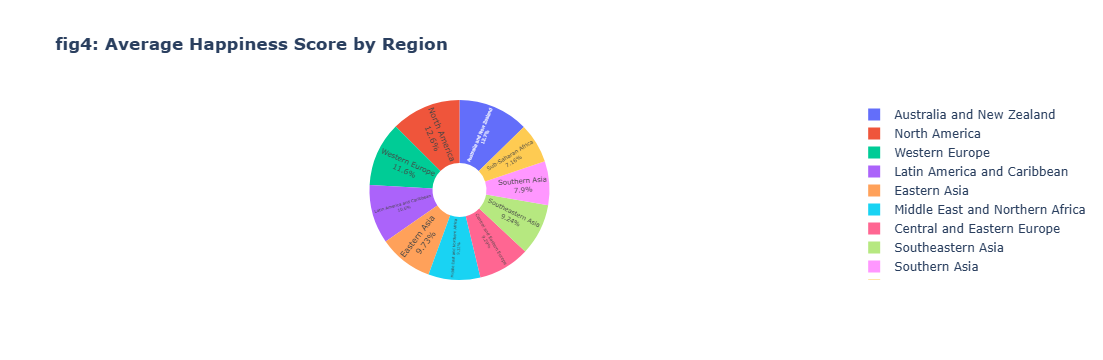

In [39]:
import pandas as pd
import plotly.express as px

# 1. Load the data
df = pd.read_csv('final_2016_imputed.csv')

# 2. Aggregate data: Calculate the average Happiness Score per Region
region_happiness = df.groupby('Region')['Happiness Score'].mean().reset_index()

# 3. Create the Pie Chart (fig4)
fig4 = px.pie(
    region_happiness, 
    values='Happiness Score', 
    names='Region', 
    title='<b>fig4: Average Happiness Score by Region</b>',
    template='plotly_white',
    hole=0.3 # Optional: makes it a donut chart for a more modern look
)

# 4. Enhance the labels
fig4.update_traces(textposition='inside', textinfo='percent+label')

# 5. Show the chart
fig4.show()

C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_19040\1278705486.py:8: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



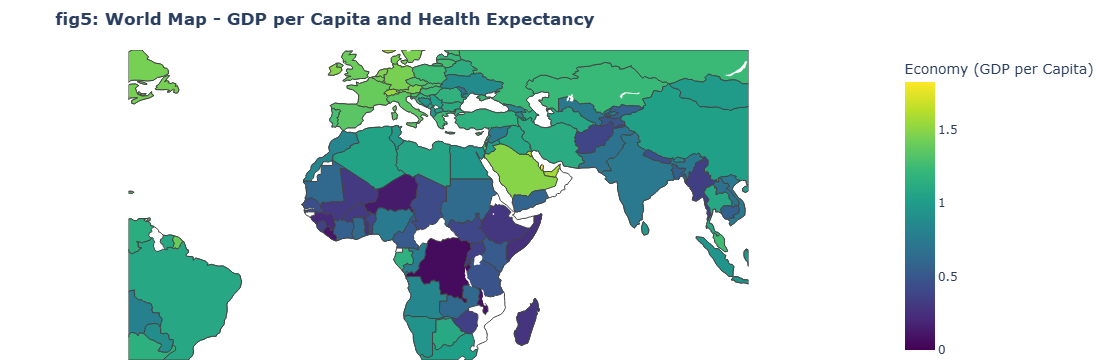

In [41]:
import pandas as pd
import plotly.express as px

# 1. تحميل البيانات المنقحة
df = pd.read_csv('final_2016_imputed.csv')

# 2. إنشاء خريطة العالم (Choropleth Map)
fig5 = px.choropleth(
    df,
    locations="Country",         # اسم العمود الذي يحتوي على أسماء الدول
    locationmode="country names", # إخبار المكتبة أن المواقع هي أسماء دول
    color="Economy (GDP per Capita)", # اللون يعبر عن الاقتصاد
    hover_name="Country",         # اسم الدولة يظهر كعنوان عند تمرير الماوس
    hover_data=["Health (Life Expectancy)", "Happiness Score"], # البيانات الإضافية في الـ Tooltip
    title="<b>fig5: World Map - GDP per Capita and Health Expectancy</b>",
    color_continuous_scale=px.colors.sequential.Viridis, # تدرج لوني احترافي
    template="plotly_white"
)

# 3. تحسين مظهر الخريطة
fig5.update_layout(
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type='equirectangular'
    ),
    margin={"r":0,"t":50,"l":0,"b":0}
)

# 4. عرض الخريطة
fig5.show()

In [43]:
import pandas as pd
import plotly.express as px

# 1. Load the cleaned data
df = pd.read_csv('final_2016_imputed.csv')

# --- FIG 2: Correlation Heatmap ---
sub_cols = ['Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 
            'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Happiness Score']
corr_matrix = df[sub_cols].corr()
fig2 = px.imshow(corr_matrix, text_auto='.2f', color_continuous_scale='RdBu_r', 
                 title="<b>Correlation Heatmap</b>")

# --- FIG 3: Scatter Plot ---
fig3 = px.scatter(df, x="Economy (GDP per Capita)", y="Happiness Score", color="Region", 
                 hover_name="Country", title="<b>Happiness vs GDP by Region</b>")

# --- FIG 4: Pie Chart ---
region_happiness = df.groupby('Region')['Happiness Score'].mean().reset_index()
fig4 = px.pie(region_happiness, values='Happiness Score', names='Region', 
              title='<b>Avg Happiness Score by Region</b>')

# --- FIG 5: World Map ---
fig5 = px.choropleth(df, locations="Country", locationmode="country names", 
                    color="Economy (GDP per Capita)", hover_name="Country", 
                    hover_data=["Health (Life Expectancy)"], title="<b>Global GDP Distribution</b>")

# --- CREATE THE DASHBOARD ---
# We write each figure to a single HTML file
with open('dashboard.html', 'w') as f:
    # Basic HTML setup
    f.write("<html><head><title>Happiness Report Dashboard</title></head>")
    f.write("<body style='font-family: Arial; margin: 40px;'>")
    f.write("<h1 style='text-align: center;'>World Happiness 2016 Interactive Dashboard</h1>")
    f.write("<hr>")
    
    # Writing the figures. include_plotlyjs='cdn' ensures the file isn't too large
    # but still works when you have an internet connection.
    f.write(fig2.to_html(full_html=False, include_plotlyjs='cdn'))
    f.write(fig3.to_html(full_html=False, include_plotlyjs='cdn'))
    f.write(fig4.to_html(full_html=False, include_plotlyjs='cdn'))
    f.write(fig5.to_html(full_html=False, include_plotlyjs='cdn'))
    
    f.write("<p style='text-align: center;'>End of Report</p>")
    f.write("</body></html>")

print("The dashboard has been successfully created!")

C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_19040\3070075702.py:24: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



The dashboard has been successfully created!


In [45]:
from IPython.display import IFrame

# This will display the dashboard inside your notebook cell
IFrame(src='dashboard.html', width='100%', height='800px')

Executive Narrative: Insights from the World Happiness Report
Introduction
This dashboard provides a comprehensive analysis of the factors that influenced global happiness in 2016. By examining economic output, health, and regional trends, we can move beyond simple rankings to understand the "why" behind a country’s well-being.

1. The DNA of Happiness (Correlation Heatmap)
Our journey begins with the Correlation Heatmap (fig2), which identifies the underlying drivers of the Happiness Score.

Key Insight: The data reveals that Economy (GDP per Capita) and Health (Life Expectancy) are the strongest predictors of happiness, with correlation coefficients of 0.79 and 0.77 respectively.

The Social Pillar: Interestingly, Family (Social Support) follows closely as a vital factor.

Conclusion: This chart proves that while money is a major factor, a combination of physical health and social safety nets forms the "Gold Standard" for high-ranking nations.

2. Wealth vs. Well-being (Scatter Plot)
The Scatter Plot (fig3) visualizes the direct relationship between economic power and the Happiness Score across different world regions.

The Regional Divide: There is a clear upward diagonal trend. Regions like Western Europe and North America cluster in the top-right corner, indicating that high GDP is consistently paired with high happiness.

The Reality of Developing Nations: In contrast, countries like Sudan (with a GDP score of 0.63 and a Happiness Score of 4.1) fall in the lower-left quadrant. This chart highlights that while a higher GDP generally leads to higher happiness, the regional "starting points" vary significantly due to local political and social factors.

3. Global Distribution of Joy (Pie Chart)
The Pie Chart (fig4) aggregates these scores by region to provide a global perspective.

Dominant Regions: Australia and New Zealand, North America, and Western Europe hold the largest shares of the "happiness pie," reflecting their consistently high average scores (above 6.5).

The Opportunity Gap: The smaller slices representing Sub-Saharan Africa and Southern Asia emphasize where global development efforts are most needed to improve quality of life.

4. Mapping Prosperity and Health (World Map)
Finally, the Interactive World Map (fig5) provides a geographic reality check, displaying GDP per Capita across the globe.

The Hidden Layer: By hovering over the map, the Healthy Life Expectancy tooltip reveals a crucial connection. In many high-GDP countries, health scores are also exceptionally high, suggesting that economic wealth is being successfully reinvested into healthcare infrastructure.

Visualizing Disparity: The map clearly shows a "Happiness Gap" between the Northern and Southern hemispheres, primarily driven by the economic resources available to each nation.

Final Conclusion
The data suggests that Happiness is a multi-dimensional metric. While the Economy is the most significant engine of happiness, it is most effective when paired with Longevity (Health) and Social Freedom. For nations at the lower end of the scale, such as Sudan, the path to increased happiness involves not just economic growth, but also addressing the gaps in health and individual freedoms that current data shows are lagging.

This dashboard serves as a tool for policymakers and researchers to identify which levers—be they economic, social, or medical—need to be pulled to improve the collective well-being of their citizens.